In [1]:
import torch
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

pd.set_option('display.max_colwidth', None)

In [11]:
# dataset = torch.load("/home/sgoyal/Projects/llm_asr_clarification/shared/datasets/logp_deltas/train_Qwen3-8B-FP8.pt")
# dataset = torch.load("/home/sgoyal/Projects/llm_asr_clarification/shared/datasets/logp_deltas/train_8b.pt")
dataset = torch.load("/home/sgoyal/Projects/llm_asr_clarification/shared/datasets/logp_deltas/train_32b.pt")
meeting_name = 'TS3005d'
training_meetings_path = Path("/home/sgoyal/Projects/llm_asr_clarification//shared/datasets/amicorpus/train")

In [12]:
print(dataset[meeting_name]['segment_deltas'].shape)
print(dataset[meeting_name]['logps'].shape)

torch.Size([1356])
torch.Size([1357, 10])


In [13]:
with open(training_meetings_path / meeting_name / "transcripts" / "custom_transcript_gt_segments.txt", "r") as f:
    transcript_lines = [line.strip() for line in f]
print(len(transcript_lines))

1356


In [14]:
with open(training_meetings_path / meeting_name / "transcripts" / "parsed_diarized_gt.txt", "r") as f:
    gt_lines = [line.strip() for line in f]
print(len(gt_lines))

1356


In [15]:
print(f"Base Transcript LogPs: {dataset[meeting_name]['logps'][0].sum(dim=-1)}")
print(dataset[meeting_name]['logps'][0,9])
print(dataset[meeting_name]['logps'][:,9].mean(dim=0))

Base Transcript LogPs: -341.79313114488707
tensor(-42.7413, dtype=torch.float64)
tensor(-42.6488, dtype=torch.float64)


In [16]:
logps = dataset[meeting_name]["logps"]
argmaxes = ((logps[1:] - logps[1:].mean(dim=0)) / logps[1:].std(dim=0)).argmax(dim=1) + 1

# print(argmaxes)

In [17]:
df = pd.DataFrame({
    "asr_line": transcript_lines,
    "gt_line": gt_lines,
    "segment_delta": dataset[meeting_name]['segment_deltas'],
    "idx": argmaxes
    # "logp": dataset[meeting_name]['logps'][1:,].sum(dim=-1)
})
# df = df.sort_values(by='logp', ascending=False)
df = df.sort_values(by='segment_delta', ascending=False)

In [18]:
df.head(20)

,asr_line,gt_line,segment_delta,idx
757,(1482.27 - 1505.55)[Speaker C]: We could use the scroll wheel. We could just adjust the regular scroll wheel. You have to tap the options window button here and scroll down with the button. No one else scroll wheel. I think we should use the sample speaker.,(1482.27 - 1505.55)[Speaker D]: We could use I think we should scrap the sample speaker.,14.772936,6
88,"(232.96 - 256.6)[Speaker C]: OK, it's also nice to see that we make a small menu, the options menu are becoming available when pressing the scroll button, and the opportunity to use the date text, which is still used, and we think that it's very handy to put it not under the options menu, but you know,","(232.96 - 256.6)[Speaker C]: Okay, um it's also uh nice to see that um we made a small uh menu, uh the options menu uh becoming available when pressing the uh scroll uh button, and the opportunity to use the teletext, whi which is used uh which should still be used and we think that it's uh very handy to put it uh not uh under the options menu, but in uh Yes.",9.901545,3
6,"(12.41 - 24.03)[Speaker A]: As you may notice, I created separate folders because it was maybe a little busy in our shared project document folder.",(12.41 - 24.03)[Speaker A]: Um as you may have noticed I uh created separate folders because it was uh tending to get a little busy in our uh shared project documents uh folder.,9.899616,1
831,(1607.76 - 1611.67)[Speaker A]: But I think the only option is to top the set speaker to knock the samples,(1607.76 - 1611.67)[Speaker A]: But I think the only option is to drop the uh sample speaker.,8.335973,6
978,"(1889.38 - 1890.55)[Speaker A]: 12-year-old, 15.",(1889.38 - 1890.55)[Speaker A]: Twelve Euro fifty.,8.149187,7
141,(380.46 - 382.87)[Speaker A]: Okay.,"(380.46 - 382.87)[Speaker A]: Okay, the evaluation criteria, huh?",7.464481,2
1147,(2244.14 - 2247.14)[Speaker D]: only thing that we work through.,"(2244.14 - 2247.14)[Speaker D]: Only thing that we worked through, past each other.",7.354401,9
1076,(2088.81 - 2093.07)[Speaker D]: or maybe session of 5 minutes to get over something and then work.,"(2088.81 - 2093.07)[Speaker D]: Yeah, no, or maybe session of five minutes together or something, and then work separate.",6.662141,10
650,"(1305.97 - 1319.49)[Speaker A]: We're going to calculate the production costs, if they are under or at 12, you know, 50. We're good. And if you're not, we're going to redesign it. We have to do that. We're ready for quick. I think yes.","(1305.97 - 1319.49)[Speaker A]: Um and we're going to calculate the production costs, and if they are uh under or at twelve Euro fifty, we're good, and if they're not we're going to uh re-design, but we have to do that uh very very quick I think, yes.",6.645051,7
20,(48.28 - 51.18)[Speaker A]: I'm going to post it.,(48.28 - 51.18)[Speaker A]: And we have a evaluation left here.,6.636272,2


<Axes: >

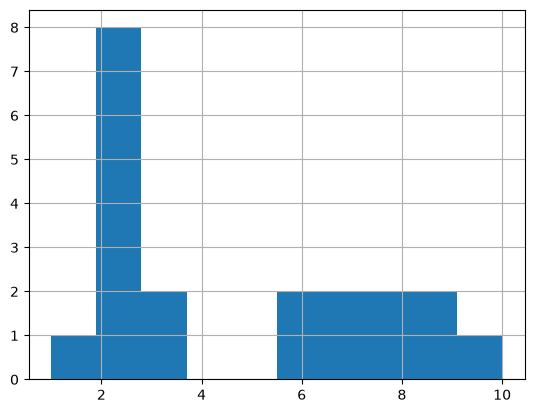

In [19]:
df.head(20)['idx'].hist()

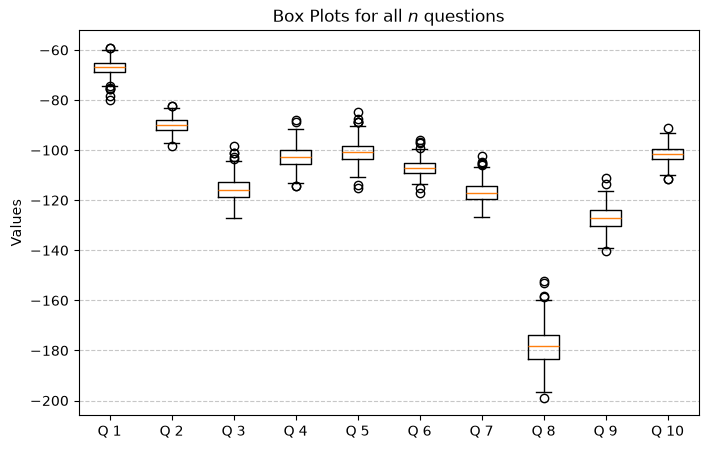

In [84]:
logps = dataset[meeting_name]['logps']


plt.figure(figsize=(8, 5))

# Matplotlib plots columns automatically when given a 2D array
plt.boxplot(logps.numpy(), tick_labels=[f"Q {i+1}" for i in range(logps.numpy().shape[1])])

plt.title("Box Plots for all $n$ questions")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

torch.Size([504, 10])


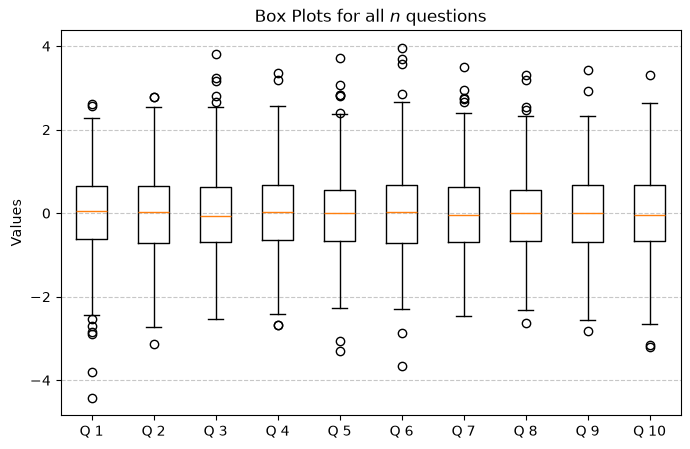

In [85]:
deltas = (logps[1:] - logps[1:].mean(dim=0)) / logps[1:].std(dim=0)

# deltas = (logps[1:] - logps[0:1])

print(deltas.shape)

plt.figure(figsize=(8, 5))

# Matplotlib plots columns automatically when given a 2D array
plt.boxplot(deltas, tick_labels=[f"Q {i+1}" for i in range(deltas.shape[1])])

plt.title("Box Plots for all $n$ questions")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [20]:
df = pd.DataFrame({
    "asr_line": transcript_lines,
    "gt_line": gt_lines,
    "delta": deltas.max(axis=1),
})
df = df.sort_values(by='delta', ascending=False)

In [28]:
df.head(5)

,asr_line,gt_line,delta
144,"(397.76 - 411.51)[Speaker C]: So basically, in order to save our two euros, I was thinking that we could have a sense of the same shape but just have it flattened.","(397.76 - 411.51)[Speaker C]: So basically, um in order to save our two Euros um I was thinking that we could have essentially the same shape, but just have it flattened.",10.207671
231,(606.84 - 613.58)[Speaker D]: for maybe we could have something but maybe if what is that said that's that's that's that's a thing that we've got.,"(606.84 - 613.58)[Speaker D]: Well maybe we could add something, but maybe if What do you th We're trying to save money, so.",7.868597
232,(613.58 - 618.09)[Speaker D]: if we're happy with the design as they put 20 money if we don't have to,"(613.58 - 618.09)[Speaker D]: Yeah, if we're happy with the design there's no point in spending money, if we don't have to.",4.697014
56,"(170.4 - 177.63)[Speaker D]: If you do need buttons, you can flip it over on the some there. But mainly is speak tracking notion.","(170.4 - 177.63)[Speaker D]: If you do need buttons, you can flip it over, and there's some there, um but mainly it's speech recognition.",4.308403
109,(303.07 - 304.65)[Speaker D]: It's kind of real thanks.,"(303.07 - 304.65)[Speaker C]: It's out of the way as well, I suppose, so.",4.123137


In [32]:
base = (logps[0:1] - logps[1:].mean(dim=0)) / logps[1:].std(dim=0)
print(base)

tensor([[-0.4206, -0.0640, -0.6802,  1.3970, -0.2627, -0.5618,  0.5515, -1.3768,
         -1.1155,  1.0461]], dtype=torch.float64)


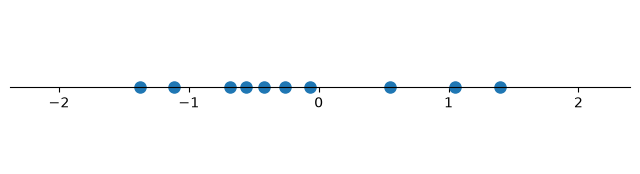

In [31]:
data = base.view(-1)

# 2. Setup a clean 1D axis layout
fig, ax = plt.subplots(figsize=(8, 2))

# Hide top, right, and left borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Position the bottom spine at zero and hide the Y-axis ticks
ax.spines['bottom'].set_position('zero')
ax.get_yaxis().set_visible(False)

# 3. Plot the 1D data points (Y values are all zeros)
# 'o' creates the dots, and 'None' ensures no connecting lines
ax.plot(data, np.zeros_like(data), marker='o', linestyle='None', markersize=8)

# Adjust view limits so points aren't cut off
ax.set_xlim(min(data) - 1, max(data) + 1)

plt.show()

<Axes: >

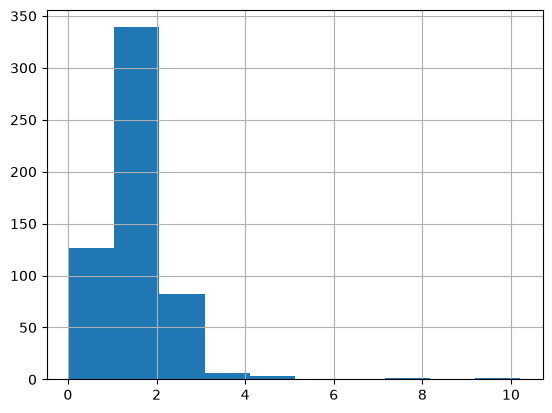

In [27]:
df["delta"].hist()